## Dog vs Cat Classification : CNN

### Dataset: Dogs vs. Cats

**Source:** Kaggle  
**Dataset Link:** [Dogs vs. Cats Dataset](https://www.kaggle.com/datasets/salader/dogsvscats)

**Description:** This dataset contains images of dogs and cats for a binary image classification task using deep learning and Convolutional Neural Networks (CNNs).

**Task:** Classify images into two categories: `Dogs` and `Cats`.

**Access Method:** The dataset is accessed programmatically using `kagglehub`, without manually downloading files through a browser.

In [1]:
import kagglehub
from pathlib import Path

# Automatically download and cache the dataset
dataset_path = kagglehub.dataset_download(
    "salader/dogsvscats"
)

dataset_path = Path(dataset_path)

print("Dataset location:", dataset_path)

# Display the folder structure
for item in list(dataset_path.iterdir()):
    print(item.name)

c:\Users\alili\100_days_Deep_Learning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 1.06G/1.06G [05:09<00:00, 3.69MB/s]

Extracting files...


Dataset location: C:\Users\alili\.cache\kagglehub\datasets\salader\dogsvscats\versions\1
catsvsdogs
test
train


In [2]:
from pathlib import Path

dataset_path = Path(
    r"C:\Users\alili\.cache\kagglehub\datasets\salader\dogsvscats\versions\1"
)

for item in dataset_path.iterdir():
    print(item.name, "->", "Folder" if item.is_dir() else "File")

catsvsdogs -> Folder
test -> Folder
train -> Folder


In [3]:
from pathlib import Path

train_dir = dataset_path / "train"
test_dir = dataset_path / "test"

print("Training folders:")
for folder in train_dir.iterdir():
    print(folder.name, "->", "Folder" if folder.is_dir() else "File")

print("\nTesting folders:")
for folder in test_dir.iterdir():
    print(folder.name, "->", "Folder" if folder.is_dir() else "File")

Training folders:
cats -> Folder
dogs -> Folder

Testing folders:
cats -> Folder
dogs -> Folder


In [4]:
import tensorflow as tf

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(150, 150),
    batch_size=32,
    label_mode="binary",
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(150, 150),
    batch_size=32,
    label_mode="binary",
    shuffle=False
)

print("Classes:", train_ds.class_names)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.
Classes: ['cats', 'dogs']


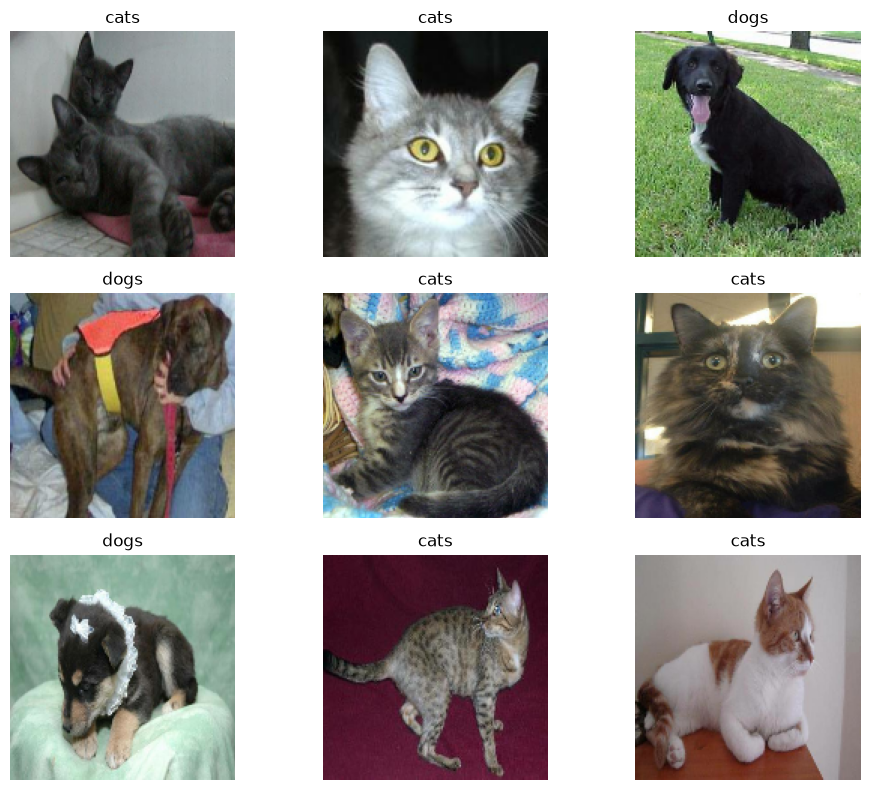

In [5]:
import matplotlib.pyplot as plt

# Get one batch of training images
images, labels = next(iter(train_ds))

# Display 9 images
plt.figure(figsize=(10, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    plt.imshow(images[i].numpy().astype("uint8"))

    label = int(labels[i].numpy()[0])
    class_name = train_ds.class_names[label]

    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
# Normalize pixel values from [0, 255] to [0, 1]
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

test_ds = test_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

# Verify the pixel values
for images, labels in train_ds.take(1):
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [7]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Dataset pipelines optimized!")

Dataset pipelines optimized!


In [8]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(150, 150, 3)),

    # Convolutional block 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional block 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional block 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification head
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [10]:
history = model.fit(
    train_ds,
    epochs=10,
    validation_data=test_ds
)

Epoch 1/10


c:\Users\alili\100_days_Deep_Learning\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


625/625 ━━━━━━━━━━━━━━━━━━━━ 1096s 2s/step - accuracy: 0.6261 - loss: 0.6349 - val_accuracy: 0.6872 - val_loss: 0.5853
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 890s 1s/step - accuracy: 0.7526 - loss: 0.5080 - val_accuracy: 0.7864 - val_loss: 0.4517
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 883s 1s/step - accuracy: 0.8038 - loss: 0.4273 - val_accuracy: 0.8270 - val_loss: 0.3961
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 884s 1s/step - accuracy: 0.8411 - loss: 0.3551 - val_accuracy: 0.7828 - val_loss: 0.4565
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 881s 1s/step - accuracy: 0.8769 - loss: 0.2931 - val_accuracy: 0.8362 - val_loss: 0.3761
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 899s 1s/step - accuracy: 0.9036 - loss: 0.2370 - val_accuracy: 0.8508 - val_loss: 0.3806
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 880s 1s/step - accuracy: 0.9269 - loss: 0.1838 - val_accuracy: 0.8500 - val_loss: 0.4006
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 876s 1s/step - accuracy: 0.9413 - loss: 0.1500 - val_accuracy: 0.84

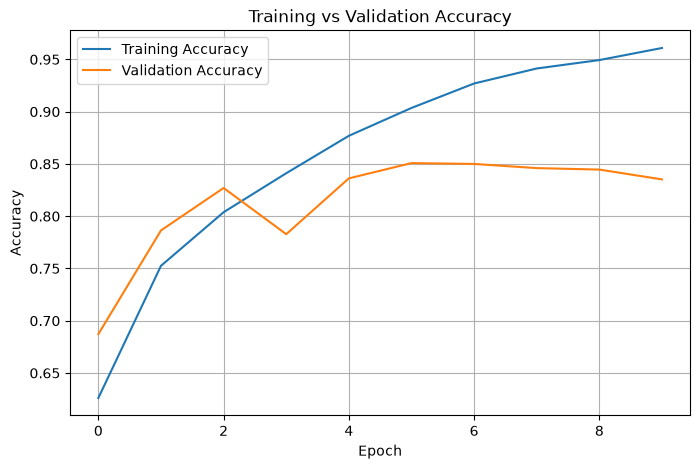

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

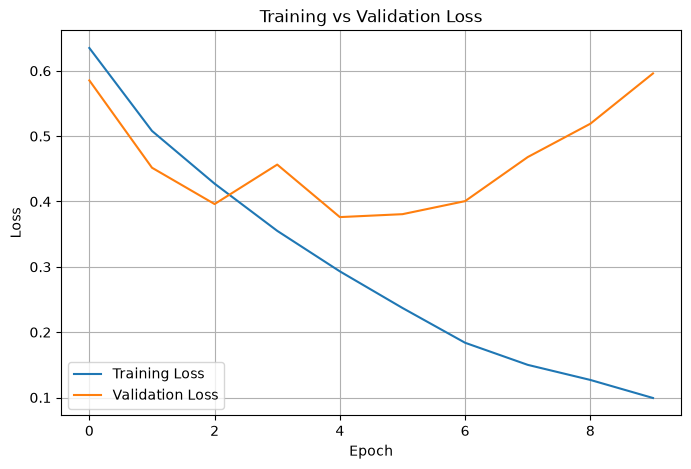

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

157/157 ━━━━━━━━━━━━━━━━━━━━ 50s 317ms/step - accuracy: 0.8352 - loss: 0.5960
Test Loss: 0.5960
Test Accuracy: 0.8352
Test Accuracy: 83.52%


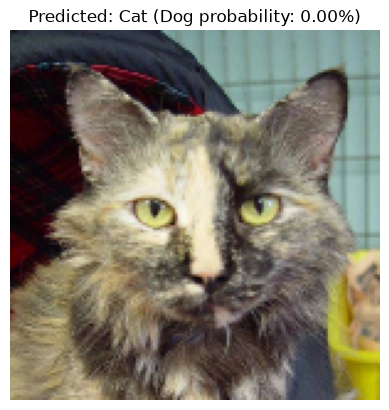

Image: cat.10.jpg
Prediction: Cat
Dog probability: 0.0000


In [14]:
import numpy as np
from pathlib import Path
from tensorflow.keras.utils import load_img, img_to_array

# Select an image from either class
image_path = next((test_dir / "cats").glob("*"))

# To test a dog instead, use:
# image_path = next((test_dir / "dogs").glob("*"))

img = load_img(image_path, target_size=(150, 150))
img_array = img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array, verbose=0)[0][0]

# Labels are alphabetically ordered: cats=0, dogs=1
predicted_class = "Dog" if prediction >= 0.5 else "Cat"

plt.imshow(img)
plt.title(
    f"Predicted: {predicted_class} "
    f"(Dog probability: {prediction:.2%})"
)
plt.axis("off")
plt.show()

print("Image:", image_path.name)
print("Prediction:", predicted_class)
print(f"Dog probability: {prediction:.4f}")